<a href="https://colab.research.google.com/github/adilsher-dev/DEEP-LEARNING/blob/main/TraininigCNNwithTensorBoardCallback.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy: 0.9454 - loss: 0.1823 - val_accuracy: 0.9823 - val_loss: 0.0590
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9819 - loss: 0.0582 - val_accuracy: 0.9814 - val_loss: 0.0532
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9882 - loss: 0.0384 - val_accuracy: 0.9871 - val_loss: 0.0366
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9916 - loss: 0.0268 - val_accuracy: 0.9856 - val_loss: 0.0413
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9933 - loss: 0.0203 - val_accuracy: 0.9872 - val_loss: 0.0374
Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.7486 - loss: 0.9177 - val_accuracy: 0.9069 - val_loss: 0.3156
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9184 - loss: 0.2786 - val_accuracy: 0.9346 - val_loss: 0.2167
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9369 - loss: 0.2137 - val_accu

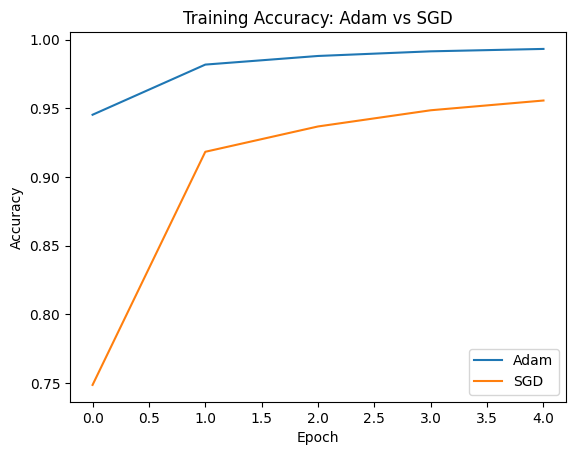

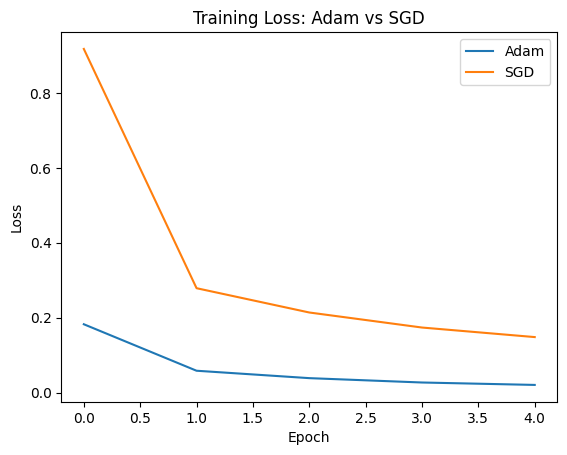

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


(X_train, Y_train), (X_test, Y_test) = tf.keras.datasets.mnist.load_data()


X_train = X_train / 255.0
X_test = X_test / 255.0


X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)



def create_cnn():
    model = tf.keras.models.Sequential([
        tf.keras.layers.Conv2D(
            32, (3, 3),
            activation='relu',
            strides=2,
            input_shape=(28, 28, 1)
        ),

        tf.keras.layers.Conv2D(
            64, (3, 3),
            activation='relu',
            strides=2
        ),

        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(128, activation='relu'),

        tf.keras.layers.Dense(10, activation='softmax')
    ])

    return model



adam_callback = tf.keras.callbacks.TensorBoard(
    log_dir='./logs/adam'
)

sgd_callback = tf.keras.callbacks.TensorBoard(
    log_dir='./logs/SGD'
)



adam_model = create_cnn()

adam_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

adam_history = adam_model.fit(
    X_train,
    Y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_test, Y_test),
    callbacks=[adam_callback]
)



sgd_model = create_cnn()

sgd_model.compile(
    optimizer='SGD',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

sgd_history = sgd_model.fit(
    X_train,
    Y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_test, Y_test),
    callbacks=[sgd_callback]
)



adam_loss, adam_accuracy = adam_model.evaluate(
    X_test, Y_test, verbose=0
)

sgd_loss, sgd_accuracy = sgd_model.evaluate(
    X_test, Y_test, verbose=0
)

print("Adam Test Accuracy:", adam_accuracy)
print("Adam Test Loss:", adam_loss)

print("SGD Test Accuracy:", sgd_accuracy)
print("SGD Test Loss:", sgd_loss)



plt.plot(adam_history.history['accuracy'], label='Adam')
plt.plot(sgd_history.history['accuracy'], label='SGD')

plt.title('Training Accuracy: Adam vs SGD')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()



plt.plot(adam_history.history['loss'], label='Adam')
plt.plot(sgd_history.history['loss'], label='SGD')

plt.title('Training Loss: Adam vs SGD')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [2]:
%load_ext tensorboard
%tensorboard --logdir logs

<IPython.core.display.Javascript object>